## Import Library

In [1]:
#202431013_Tashfia Wahdah Fuady
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

### 2. Membaca dataset


In [2]:
#202431013_Tashfia Wahdah Fuady
df = pd.read_csv("tempat_wisata_bali.csv")
display(df.head())

print("Ukuran dataset:", df.shape)

,nama,kategori,kabupaten_kota,rating,preferensi,link,latitude,longitude
0,Taman Mumbul Sangeh,Alam,Kabupaten Badung,4.6,Wisata Alam,https://www.google.com/maps/place/Taman+Mumbul...,-8.483959,115.2122881
1,Sangeh Monkey Forest,Alam,Kabupaten Badung,4.6,Wisata Alam,https://www.google.com/maps/place/Sangeh+Monke...,-8.4817743,115.2067391
2,Objek Wisata Sangeh,Umum,Kabupaten Badung,4.6,Wisata Umum,https://www.google.com/maps/place/Objek+Wisata...,-8.4815663,115.2065458
3,Satria Gatotkaca Park,Umum,Kabupaten Badung,4.6,Wisata Umum,https://www.google.com/maps/place/Satria+Gatot...,-8.7443882,115.1788673
4,Desa Wisata Penarungan,Umum,Kabupaten Badung,5.0,Wisata Umum,https://www.google.com/maps/place/Desa+Wisata+...,-8.5396366,115.198893


Ukuran dataset: (761, 8)


### 3. Melihat informasi dataset


In [3]:
#202431013_Tashfia Wahdah Fuady
print("Informasi dataset:")
df.info()

print("\nDeskripsi statistik:")
display(df.describe())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 761 entries, 0 to 760
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   nama            761 non-null    str    
 1   kategori        761 non-null    str    
 2   kabupaten_kota  761 non-null    str    
 3   rating          751 non-null    float64
 4   preferensi      761 non-null    str    
 5   link            761 non-null    str    
 6   latitude        761 non-null    str    
 7   longitude       761 non-null    str    
dtypes: float64(1), str(7)
memory usage: 271.6 KB

Deskripsi statistik:


,rating
count,751.000000
mean,4.536884
std,0.263839
min,3.000000
25%,4.400000
50%,4.600000
75%,4.700000
max,5.000000


#### Mengubah koordinat menjadi numerik


In [4]:
#202431013_Tashfia Wahdah Fuady
for kolom in ["latitude", "longitude"]:
    df[kolom] = pd.to_numeric(
        df[kolom].astype(str).str.replace(",", ".", regex=False),
        errors="coerce")

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

#### Menghapus data duplikat

In [5]:
#202431013_Tashfia Wahdah Fuady
df = df.drop_duplicates().copy()
print("Ukuran dataset setelah menghapus duplikat:", df.shape)

Ukuran dataset setelah menghapus duplikat: (758, 8)


#### Mengisi missing value fitur numerik dengan median


In [6]:
#202431013_Tashfia Wahdah Fuady
fitur_numerik_awal = ["rating", "latitude", "longitude"]

for kolom in fitur_numerik_awal:
    df[kolom] = df[kolom].fillna(df[kolom].median())

### 4. Memisahkan fitur numerik


In [7]:
#202431013_Tashfia Wahdah Fuady
fitur_numerik = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Jumlah fitur numerik:", len(fitur_numerik))
print("Daftar fitur numerik:")
print(fitur_numerik)

Jumlah fitur numerik: 3
Daftar fitur numerik:
['rating', 'latitude', 'longitude']


### 5. Memisahkan fitur kategorikal


In [8]:
#202431013_Tashfia Wahdah Fuady
fitur_kategorikal = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Jumlah fitur kategorikal:", len(fitur_kategorikal))
print("Daftar fitur kategorikal:")
print(fitur_kategorikal)

Jumlah fitur kategorikal: 5
Daftar fitur kategorikal:
['nama', 'kategori', 'kabupaten_kota', 'preferensi', 'link']


C:\Users\TasfiaWF\AppData\Local\Temp\ipykernel_16436\3875137124.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  fitur_kategorikal = df.select_dtypes(include=["object", "category"]).columns.tolist()


### 6. Menampilkan nilai unik setiap fitur kategorikal


In [9]:
#202431013_Tashfia Wahdah Fuady
for kolom in fitur_kategorikal:
    print(f"\nNilai unik pada kolom {kolom}:")
    print(df[kolom].unique())


Nilai unik pada kolom nama:
<ArrowStringArray>
[                         'Taman Mumbul Sangeh',
                         'Sangeh Monkey Forest',
                          'Objek Wisata Sangeh',
                        'Satria Gatotkaca Park',
                       'Desa Wisata Penarungan',
                                    'Waterblow',
                             'Pantai Mengening',
                  'Kawasan Pariwisata Nusa Dua',
                  'Gunung Payung Cultural Park',
     'Taman Anyar - Traditional Balinese House',
 ...
     'TAMAN INSPIRASI dan WARUNG MUNTIG SIOKAN',
                      'Agung Jagatnatha Temple',
                               'Pantai Bangsal',
                             'Museum Le Mayeur',
 'Barong Tanah Kilap - Sari Wisata Budaya BALI',
                     'Tugu Peringatan Bom Bali',
                    'Museum Lukisan Sidik Jari',
                              'Taman Kumbasari',
                 'Taman Janggan Renon Denpasar',
                

### 7. Mengubah fitur kategorikal menjadi angka menggunakan LabelEncoder


In [10]:
#202431013_Tashfia Wahdah Fuady
label_encoders = {}

for kolom in fitur_kategorikal:
    encoder = LabelEncoder()
    df[kolom + "_encoded"] = encoder.fit_transform(df[kolom].astype(str))
    label_encoders[kolom] = encoder

print("\nHasil encoding:")
display(df.head())


Hasil encoding:


,nama,kategori,kabupaten_kota,rating,preferensi,link,latitude,longitude,nama_encoded,kategori_encoded,kabupaten_kota_encoded,preferensi_encoded,link_encoded
0,Taman Mumbul Sangeh,Alam,Kabupaten Badung,4.6,Wisata Alam,https://www.google.com/maps/place/Taman+Mumbul...,-8.483959,115.212288,613,0,0,0,618
1,Sangeh Monkey Forest,Alam,Kabupaten Badung,4.6,Wisata Alam,https://www.google.com/maps/place/Sangeh+Monke...,-8.481774,115.206739,555,0,0,0,560
2,Objek Wisata Sangeh,Umum,Kabupaten Badung,4.6,Wisata Umum,https://www.google.com/maps/place/Objek+Wisata...,-8.481566,115.206546,351,3,0,3,355
3,Satria Gatotkaca Park,Umum,Kabupaten Badung,4.6,Wisata Umum,https://www.google.com/maps/place/Satria+Gatot...,-8.744388,115.178867,562,3,0,3,567
4,Desa Wisata Penarungan,Umum,Kabupaten Badung,5.0,Wisata Umum,https://www.google.com/maps/place/Desa+Wisata+...,-8.539637,115.198893,169,3,0,3,173


### 8. Memisahkan fitur X dan target Y


In [11]:
#202431013_Tashfia Wahdah Fuady
# Nama, link, dan preferensi tidak digunakan sebagai prediktor.
fitur_X = ["rating","latitude","longitude","kabupaten_kota_encoded"]

X = df[fitur_X]
y = df["kategori_encoded"]

print("Fitur X:")
display(X.head())

print("\nTarget Y:")
display(y.head())

Fitur X:


,rating,latitude,longitude,kabupaten_kota_encoded
0,4.6,-8.483959,115.212288,0
1,4.6,-8.481774,115.206739,0
2,4.6,-8.481566,115.206546,0
3,4.6,-8.744388,115.178867,0
4,5.0,-8.539637,115.198893,0



Target Y:


0    0
1    0
2    3
3    3
4    3
Name: kategori_encoded, dtype: int64

### 9. Membagi data latih dan data uji


In [12]:
#202431013_Tashfia Wahdah Fuady
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 568
Jumlah data uji: 190


### 10. Membuat dan melatih model GaussianNB


In [13]:
#202431013_Tashfia Wahdah Fuady
model = GaussianNB()
model.fit(X_train, y_train)

print("Model Gaussian Naive Bayes berhasil dilatih.")

Model Gaussian Naive Bayes berhasil dilatih.


### 11. Melakukan prediksi data latih dan data uji

In [14]:
#202431013_Tashfia Wahdah Fuady
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print("Prediksi data training:")
print(y_pred_train[:10])

print("\nPrediksi data testing:")
print(y_pred_test[:10])

Prediksi data training:
[0 2 3 2 3 0 0 0 0 0]

Prediksi data testing:
[3 3 0 0 3 2 0 0 0 3]


### 12. Evaluasi data latih


Evaluasi Training

Confusion Matrix Training:
[[108   0   7  62]
 [ 42   0   6  45]
 [ 28   2  27  45]
 [ 84   0  12 100]]

Classification Report Training:
              precision    recall  f1-score   support

        Alam       0.41      0.61      0.49       177
      Budaya       0.00      0.00      0.00        93
    Rekreasi       0.52      0.26      0.35       102
        Umum       0.40      0.51      0.45       196

    accuracy                           0.41       568
   macro avg       0.33      0.35      0.32       568
weighted avg       0.36      0.41      0.37       568



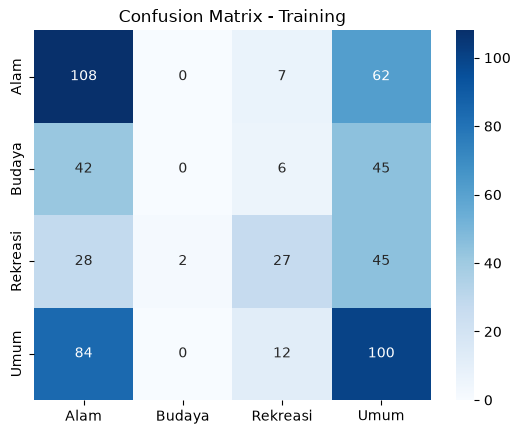

In [15]:
#202431013_Tashfia Wahdah Fuady
cm_train = confusion_matrix(y_train, y_pred_train)

print("Evaluasi Training")
print("\nConfusion Matrix Training:")
print(cm_train)

print("\nClassification Report Training:")
print(classification_report(
    y_train, y_pred_train,
    labels=np.arange(len(label_encoders["kategori"].classes_)),
    target_names=label_encoders["kategori"].classes_,
    zero_division=0
))

sns.heatmap(cm_train,annot=True,fmt="d",cmap="Blues",
    xticklabels=label_encoders["kategori"].classes_,
    yticklabels=label_encoders["kategori"].classes_,)
plt.title("Confusion Matrix - Training")
plt.show()

### 13. Evaluasi data uji


Evaluasi Testing

Confusion Matrix Testing:
[[30  0  0 23]
 [19  0  3 14]
 [ 9  1  9 16]
 [24  1  5 36]]

Classification Report Testing:
              precision    recall  f1-score   support

        Alam       0.37      0.57      0.44        53
      Budaya       0.00      0.00      0.00        36
    Rekreasi       0.53      0.26      0.35        35
        Umum       0.40      0.55      0.46        66

    accuracy                           0.39       190
   macro avg       0.32      0.34      0.31       190
weighted avg       0.34      0.39      0.35       190



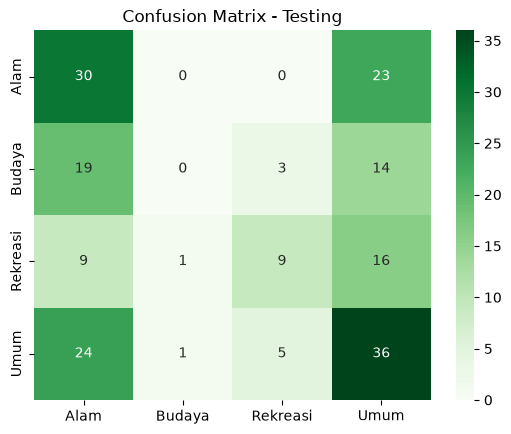

In [16]:
#202431013_Tashfia Wahdah Fuady
cm_test = confusion_matrix(y_test, y_pred_test)

print("Evaluasi Testing")
print("\nConfusion Matrix Testing:")
print(cm_test)

print("\nClassification Report Testing:")
print(classification_report(
    y_test,
    y_pred_test,
    labels=np.arange(len(label_encoders["kategori"].classes_)),
    target_names=label_encoders["kategori"].classes_,
    zero_division=0
))

sns.heatmap(cm_test,annot=True,fmt="d",cmap="Greens",
    xticklabels=label_encoders["kategori"].classes_,
    yticklabels=label_encoders["kategori"].classes_,)
plt.title("Confusion Matrix - Testing")
plt.show()

### 14. Menguji model dengan satu data baru


In [17]:
#202431013_Tashfia Wahdah Fuady
kabupaten_baru = df["kabupaten_kota"].iloc[0]

data_baru = pd.DataFrame([{
    "rating": 4.5,
    "latitude": -8.65,
    "longitude": 115.22,
    "kabupaten_kota_encoded":
        label_encoders["kabupaten_kota"].transform([kabupaten_baru])[0]
}])

hasil_prediksi = model.predict(data_baru)

kategori_prediksi = label_encoders["kategori"].inverse_transform(hasil_prediksi)

print("Evaluasi Data Baru")
print("Rating:", data_baru["rating"].iloc[0])
print("Kabupaten/Kota:", kabupaten_baru)
print("Hasil prediksi kategori wisata:", kategori_prediksi[0])

Evaluasi Data Baru
Rating: 4.5
Kabupaten/Kota: Kabupaten Badung
Hasil prediksi kategori wisata: Alam
